# 10.2.4 配套实验：反转学习中的 RW 与 GRU

在反转学习任务中，个体需要根据不断获得的奖励调整选择。经典强化学习模型用预先规定的规则描述这一过程，循环神经网络则通过拟合行为数据学习状态更新的方式。本实验以猴子的选择行为为例，比较 RW 模型与两隐藏单元 GRU 的预测，并分析两者在相同反馈下的状态变化。

完成本实验后，应能够将行为记录整理为保留实验块边界的序列，说明模型预测与反馈更新的时间关系，并结合测试表现和状态动力学讨论模型的学习规则。实验内容与教材第 10 章第 10.2.4 节对应。

## 1. 实验准备

本实验的全部计算与绘图代码均包含在本文件中。所需外部输入为行为数据 `.mat` 文件；模型参数由下文的训练过程估计。

建议将数据放在本文件同级的 `data` 目录中：

```text
reversal_learning.ipynb
data/
    SPKcounts_V20160929cue_MW_250X250ms.mat
    SPKcounts_V20160930cue_MW_250X250ms.mat
    SPKcounts_V20161005cue_MW_250X250ms.mat
    SPKcounts_V20161017cue_MW_250X250ms.mat
```

数据来自 Bartolo 与 Averbeck（2022），获取地址见参考文献。默认分析猴子 V；分析猴子 W 时，将相应文件放入数据目录并修改 `ANIMAL_NAME`。数据位于其他位置时，修改 `DATA_DIR`。

使用 Python 3.13，可通过 uv 创建环境并安装依赖。在本文件所在目录运行：

```bash
uv venv --python 3.13
uv pip install numpy scipy matplotlib torch jupyterlab ipykernel
uv run jupyter lab reversal_learning.ipynb
```

依次运行各单元，将完成数据整理、参数估计、测试评价与全部插图的生成。绘图排版函数较长，默认折叠显示；折叠单元仍需执行，可通过“运行全部单元”一次运行。计算使用 CPU，输出结果保存在 `OUTPUT_DIR` 指定的目录中。

In [ ]:
import copy
import json
import sys
from collections import Counter
from pathlib import Path
from xml.etree import ElementTree

import matplotlib
import numpy as np
import scipy
import torch
from scipy.io import loadmat
from scipy.optimize import minimize
from torch import nn

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import SVG, Markdown, display
from matplotlib import font_manager
from matplotlib.patches import FancyArrowPatch
from matplotlib.ticker import MaxNLocator


def show_table(headers, rows):
    """将表头与记录显示为表格。"""
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


def show_svg(path):
    """显示本次实验生成的矢量插图。"""
    svg = ElementTree.parse(path).getroot()
    display(SVG(filename=str(path)))


show_table(
    ["环境", "版本"],
    [
        ["Python", sys.version.split()[0]],
        ["NumPy", np.__version__],
        ["SciPy", scipy.__version__],
        ["PyTorch", torch.__version__],
        ["Matplotlib", matplotlib.__version__],
    ],
)

| 环境 | 版本 |
| --- | --- |
| Python | 3.13.15 |
| NumPy | 2.5.3 |
| SciPy | 1.18.1 |
| PyTorch | 2.14.1 |
| Matplotlib | 3.11.2 |

In [2]:
# 数据目录：默认在 Notebook 同级；也可填写数据文件夹的其他位置。
DATA_DIR = Path("data")
# 兼容数据位于上一级目录的资料排布，只改变数据的位置。
if not DATA_DIR.is_dir() and Path("../data").is_dir():
    DATA_DIR = Path("../data")

ANIMAL_NAME = "V"
TRIAL_START = 11
TRIAL_END = 70
SEED = 0
VALIDATION_FRACTION = 0.1
TEST_FRACTION = 0.1

HIDDEN_DIM = 2
LEARNING_RATE = 0.005
MAX_EPOCHS = 1000
PATIENCE = 100

GRID_SIZE = 41
MAX_ARROWS_PER_CONDITION = None  # 使用全部测试事件。
DYNAMICS_SAMPLE_SEED = 0

OUTPUT_DIR = Path("reversal_learning_results") / f"monkey_{ANIMAL_NAME}_seed{SEED}"
FIGURE_DIR = OUTPUT_DIR / "figures"

if not DATA_DIR.is_dir():
    raise FileNotFoundError("未找到数据目录，请设置 DATA_DIR 后重新运行。")

In [3]:
# 数学符号使用 Matplotlib 自带字体；中文标签优先使用本机已有的中文字体。
MODEL_COLORS = {"RW": "#c97722", "GRU": "#2864ba"}
INK = "#26313c"


def configure_figure_font():
    """选择中文字体；无可用字体时，图内标签自动切换为英文。"""
    preferred_fonts = [
        "SimSong", "Songti SC", "STSong", "Noto Serif CJK SC",
        "Source Han Serif SC", "SimSun", "PingFang SC",
        "Hiragino Sans GB", "Heiti SC", "Noto Sans CJK SC",
        "Source Han Sans SC", "Microsoft YaHei", "SimHei",
        "WenQuanYi Zen Hei",
    ]
    available_fonts = {font.name for font in font_manager.fontManager.ttflist}
    for font_name in preferred_fonts:
        if font_name in available_fonts:
            return font_manager.FontProperties(family=font_name), True
    print("未检测到中文字体：图内标签使用英文；可安装 Noto Sans CJK SC 后重新运行。")
    return font_manager.FontProperties(family="DejaVu Sans"), False


DIAGRAM_FONT, USE_CHINESE_FIGURES = configure_figure_font()


def figure_label(chinese, english):
    """中文和英文标签表达同一含义，不改变图中的计算关系。"""
    return chinese if USE_CHINESE_FIGURES else english


plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "text.color": INK,
    "axes.labelcolor": INK,
    "xtick.color": INK,
    "ytick.color": INK,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
    "mathtext.fontset": "dejavusans",
})


def _save(figure, output_dir, filename):
    """导出 SVG 矢量图，并关闭图对象以释放内存。"""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    try:
        # Matplotlib 的色标可能默认栅格化；显式保留全部矢量元素。
        for artist in figure.findobj():
            if artist.get_rasterized():
                artist.set_rasterized(False)
        figure.savefig(
            output_dir / f"{filename}.svg", bbox_inches="tight", pad_inches=0.08,
        )
    finally:
        plt.close(figure)


def save_figure(figure, name):
    """将任务图和结构图写入本实验设定的图片目录。"""
    _save(figure, FIGURE_DIR, name)


def _publication_style():
    """主图使用统一的论文排版；作用域结束后恢复其余图的样式。"""
    return plt.rc_context(
        {
            "font.family": "DejaVu Sans",
            "font.size": 8,
            "axes.labelsize": 9,
            "axes.titlesize": 9,
            "axes.linewidth": 0.7,
            "axes.facecolor": "white",
            "axes.grid": False,
            "xtick.labelsize": 8,
            "ytick.labelsize": 8,
            "xtick.major.width": 0.7,
            "ytick.major.width": 0.7,
            "xtick.major.size": 3,
            "ytick.major.size": 3,
            "legend.fontsize": 8,
            "legend.frameon": False,
            "mathtext.fontset": "dejavusans",
        }
    )

## 2. 反转学习任务与行为数据

猴子在每次试次中选择两个选项之一，随后获得奖励或无奖励反馈。每个完整实验块（block）包含 80 次试次，两个选项的奖励概率分别为 0.7 和 0.3，并在 block 中部的一个随机试次无提示地互换（Bartolo 等，2020）。由于奖励具有概率性，一次无奖励并不足以确定环境已经发生反转。

任务包含两种条件：what block 的奖励概率与图像身份有关，where block 的奖励概率与空间位置有关。数据整理时分别依据图像或位置将选择编码为动作 0 和动作 1，奖励编码为 1，无奖励编码为 0。动作 0 的含义因任务条件而异。

数据文件按实验场次（session）保存，每个 session 包含多个 block。以下分析使用猴子 V 的 4 个 session，共 96 个完整 block。每个 block 保留原始第 11–70 次试次，共 60 次。模型在保留序列的起点将状态初始化为零，反转时继续更新；这一处理不包含前 10 次试次的行为历史。

In [4]:
def plot_reversal_task():
    """绘制单试次流程和 block 内的奖励概率反转示意。"""
    from matplotlib.patches import Circle, Polygon, Rectangle

    chinese = DIAGRAM_FONT
    ink = "#202020"
    with plt.rc_context({"mathtext.fontset": "stix", "svg.fonttype": "path"}):
        figure = plt.figure(figsize=(7.2, 4.3))
        task = figure.add_axes((0.055, 0.55, 0.91, 0.41))
        task.set(xlim=(0, 10), ylim=(0, 2.9), aspect="equal")
        task.set_axis_off()

        def label(x, y, words, size=10, ha="center"):
            task.text(x, y, words, fontproperties=chinese, fontsize=size,
                      ha=ha, va="center", color=ink)

        def connect(start, finish):
            task.add_patch(FancyArrowPatch(
                start, finish, arrowstyle="->", mutation_scale=9,
                linewidth=0.8, color=ink, shrinkA=0, shrinkB=0,
            ))

        def display(center, chosen=False):
            # 方框表示刺激呈现区域；几何形状仅代指两幅不同的图像。
            task.add_patch(Rectangle((center - 1.10, 0.88), 2.20, 1.15,
                                     edgecolor=ink, facecolor="white", linewidth=0.8))
            task.add_patch(Circle((center - 0.48, 1.46), 0.15,
                                  edgecolor=ink, facecolor="#d7d7d7", linewidth=0.7))
            task.add_patch(Polygon(
                [(center + 0.48, 1.64), (center + 0.29, 1.29), (center + 0.67, 1.29)],
                edgecolor=ink, facecolor="white", linewidth=0.8,
            ))
            if chosen:
                # 虚线圈仅是解释图中的选择标记，不表示额外的实验提示。
                task.add_patch(Circle((center - 0.48, 1.46), 0.29,
                                      edgecolor=ink, facecolor="none",
                                      linestyle=(0, (3, 2)), linewidth=0.8))

        label(0.02, 2.74, "a", size=12, ha="left")
        label(0.42, 2.74, figure_label("一次试次", "One trial"), size=11, ha="left")
        for x, words in ((1.47, figure_label("呈现两个选项", "Two options")), (4.55, figure_label("选择其中一个", "Choice")), (8.25, figure_label("所选项的反馈", "Outcome"))):
            label(x, 2.30, words)
        display(1.47)
        display(4.55, chosen=True)
        connect((2.63, 1.46), (3.39, 1.46))
        task.plot([5.70, 6.60], [1.46, 1.46], color=ink, linewidth=0.8)
        task.plot([6.60, 6.60], [1.08, 1.85], color=ink, linewidth=0.8)
        connect((6.60, 1.85), (7.00, 1.85))
        connect((6.60, 1.08), (7.00, 1.08))
        label(7.22, 1.85, figure_label(r"奖励  $r_t=1$", r"Reward  $r_t=1$"), ha="left")
        label(7.22, 1.08, figure_label(r"无奖励  $r_t=0$", r"No reward  $r_t=0$"), ha="left")
        label(8.02, 1.46, figure_label("或", "or"), size=9)

        # 概率线是实验规则的示意；中间的跳变位置不对应任一真实 block。
        probability = figure.add_axes((0.14, 0.15, 0.80, 0.34))
        reversal = 40.5
        probability.step([1, reversal, 80], [0.7, 0.3, 0.3], where="post",
                         color=ink, linewidth=1.25, label=figure_label("选项 0", "Option 0"))
        probability.step([1, reversal, 80], [0.3, 0.7, 0.7], where="post",
                         color="#666666", linestyle=(0, (4, 3)), linewidth=1.1,
                         label=figure_label("选项 1", "Option 1"))
        probability.axvline(reversal, color="#999999", linestyle=(0, (1, 3)), linewidth=0.7)
        probability.set(xlim=(1, 80), ylim=(0, 1.04), xticks=(1, 80), yticks=(0, 0.3, 0.7, 1))
        probability.set_yticklabels(["0", "0.3", "0.7", "1"])
        probability.set_xlabel(figure_label("块内试次", "Trial within block"), fontproperties=chinese, fontsize=10, labelpad=3)
        probability.set_ylabel(figure_label("奖励概率", "Reward probability"), fontproperties=chinese, fontsize=10, labelpad=5)
        probability.text(0.50, 0.98, figure_label("无提示反转（位置随机）", "Uncued reversal (random trial)"), transform=probability.transAxes,
                         fontproperties=chinese, ha="center", va="top", fontsize=9,
                         bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5})
        probability.text(-0.062, 1.19, "b", transform=probability.transAxes,
                         fontproperties=chinese, fontsize=12, va="center")
        probability.text(-0.015, 1.19, figure_label("一个 block（80 次试次）", "One block (80 trials)"), transform=probability.transAxes,
                         fontproperties=chinese, fontsize=11, va="center")
        probability.legend(loc="upper right", bbox_to_anchor=(1.02, 1.33),
                           ncol=2, frameon=False, prop=chinese,
                           handlelength=1.6, columnspacing=1.2)
        probability.grid(False)
        probability.spines[["right", "top"]].set_visible(False)
        probability.spines[["left", "bottom"]].set_linewidth(0.65)
        probability.tick_params(labelsize=8.5, width=0.65, length=3)
        save_figure(figure, "reversal_task")

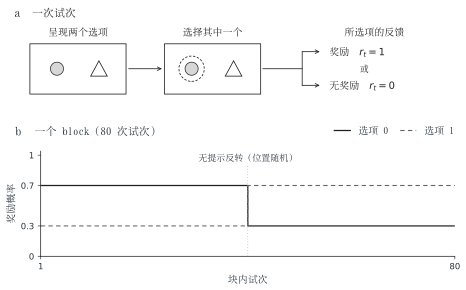

In [5]:
plot_reversal_task()
show_svg(FIGURE_DIR / "reversal_task.svg")

**图 1　反转学习任务。** 单次试次包含呈现、选择与反馈；一个 block 内两选项的奖励概率互换一次。图中刺激和反转位置均为示意。

### 读取行为记录

数据矩阵 `Y` 的每行对应一次试次。以下列号按 Python 从 0 开始计数：第 0、1 列分别记录图像与位置选择，第 2 列为奖励，第 5 列为原始试次编号，第 6 列为反转标记，第 7、8 列分别为任务条件编号与 session 内的 block 序号，第 9 列为任务类型，第 12 列表示 block 是否完成。

`load_session` 按 block 序号分组，保留任务条件编号在 1–24 且已完成的 block。反转位置从完整记录中提取，随后截取原始第 11–70 次试次。`load_blocks` 按文件名排序并汇总同一只猴子的多个 session。

In [6]:
def load_session(file_path, trial_start=11, trial_end=70):
    """从一个 MAT 文件中提取完整 block，保留指定编号范围内的试次。"""
    file_path = Path(file_path)
    behavior = loadmat(file_path, variable_names=["Y"])["Y"]

    # 文件名包含猴子名称和日期，例如 V20161005cue。
    session_token = file_path.stem.split("_")[1]
    animal_name = session_token[0]
    session_name = session_token.removesuffix("cue")

    # 以下列索引从 0 开始。BlockOrder 与 session_name 共同标识一个 block。
    block_orders = behavior[:, 8].astype(int)
    unique_orders = []
    for block_order in block_orders:
        if block_order not in unique_orders:
            unique_orders.append(block_order)

    blocks = []
    for block_order in unique_orders:
        rows = behavior[block_orders == block_order]
        block_id = int(rows[0, 7])
        block_completed = rows[:, 12] == 1
        if not (1 <= block_id <= 24) or not np.all(block_completed):
            continue

        trial_numbers = rows[:, 5].astype(int)
        task_type = int(rows[0, 9])
        block_type = "what" if task_type == 1 else "where"

        # 反转位置在截取前提取；它只用于标注，不作为模型输入。
        reversal_trials = trial_numbers[rows[:, 6] == 1]
        if len(reversal_trials) != 1:
            raise ValueError(f"{session_name} 的 block {block_order} 应有一次反转。")

        # what 任务按图像编码动作，where 任务按位置编码动作。
        action_column = 0 if task_type == 1 else 1
        actions = rows[:, action_column].astype(int)
        rewards = rows[:, 2].astype(int)
        selected = (trial_numbers >= trial_start) & (trial_numbers <= trial_end)

        blocks.append({
            "animal_name": animal_name,
            "session_name": session_name,
            "block_order": int(block_order),
            "block_type": block_type,
            "trial_numbers": trial_numbers[selected],
            "actions": actions[selected],
            "rewards": rewards[selected],
            "reversal_trial": int(reversal_trials[0]),
        })
    return blocks


def load_blocks(data_dir, animal_name, trial_start=11, trial_end=70):
    """汇总同一只猴子的全部 session，并保持固定的文件及 block 顺序。"""
    data_dir = Path(data_dir)
    pattern = f"SPKcounts_{animal_name}*cue_MW_250X250ms.mat"
    mat_files = sorted(data_dir.glob(pattern))
    if not mat_files:
        raise FileNotFoundError(f"在 {data_dir} 中未找到猴子 {animal_name} 的 MAT 数据。")

    blocks = []
    for file_path in mat_files:
        session_blocks = load_session(file_path, trial_start, trial_end)
        blocks.extend(session_blocks)
    return blocks

In [7]:
blocks = load_blocks(DATA_DIR, ANIMAL_NAME, TRIAL_START, TRIAL_END)
session_counts = Counter(block["session_name"] for block in blocks)
show_table(["session", "完整 block 数"], sorted(session_counts.items()))
print("合计 block 数：", len(blocks))
print("各 block 保留试次数：", sorted({len(block["actions"]) for block in blocks}))

example = blocks[0]
print("记录示例：", example["session_name"], "block", example["block_order"], example["block_type"])
rows = []
for t in range(min(10, len(example["actions"]))):
    rows.append([
        example["trial_numbers"][t],
        example["actions"][t],
        example["rewards"][t],
    ])
show_table(["原始试次编号", "动作 a", "奖励 r"], rows)

| session | 完整 block 数 |
| --- | --- |
| V20160929 | 24 |
| V20160930 | 24 |
| V20161005 | 24 |
| V20161017 | 24 |

合计 block 数： 96
各 block 保留试次数： [60]
记录示例： V20160929 block 1 where


| 原始试次编号 | 动作 a | 奖励 r |
| --- | --- | --- |
| 11 | 0 | 0 |
| 12 | 0 | 1 |
| 13 | 0 | 1 |
| 14 | 0 | 0 |
| 15 | 0 | 0 |
| 16 | 1 | 0 |
| 17 | 0 | 0 |
| 18 | 1 | 0 |
| 19 | 1 | 0 |
| 20 | 0 | 0 |

## 3. 数据划分与输入格式

训练集用于估计参数，验证集用于选择 GRU 的训练停止时机，测试集用于评价最终预测。数据按完整 block 划分，各 block 内的试次顺序保持不变。默认随机种子下，三个集合分别包含 78、9 和 9 个 block。

一个 block 由猴子编号、session 名称和该 session 内的 block 序号共同标识。下列代码检查三个集合的 block 是否互不重叠，并统计各集合的试次数。

In [8]:
def block_ids(blocks):
    """返回 block 的唯一标识，供数据划分核对使用。"""
    return [
        (block["animal_name"], block["session_name"], block["block_order"])
        for block in blocks
    ]


def split_blocks(blocks, validation_fraction=0.1, test_fraction=0.1, seed=0):
    """以完整 block 为单位划分训练、验证和测试集。"""
    n_blocks = len(blocks)
    n_validation = int(n_blocks * validation_fraction)
    n_test = int(n_blocks * test_fraction)
    n_train = n_blocks - n_validation - n_test

    # 只打乱 block 的排列，保留每个 block 内部的试次顺序。
    rng = np.random.default_rng(seed)
    indices = np.arange(n_blocks)
    rng.shuffle(indices)
    train_indices = indices[:n_train]
    validation_indices = indices[n_train:n_train + n_validation]
    test_indices = indices[n_train + n_validation:]

    train_blocks = [blocks[i] for i in train_indices]
    validation_blocks = [blocks[i] for i in validation_indices]
    test_blocks = [blocks[i] for i in test_indices]
    return train_blocks, validation_blocks, test_blocks


def prepare_batch(blocks, model):
    """把等长 block 整理成 inputs (T, B, 2) 与 targets (T, B)。"""
    block_inputs = []
    for block in blocks:
        inputs = np.stack([block["actions"], block["rewards"]], axis=-1)
        block_inputs.append(inputs)
    inputs = np.stack(block_inputs, axis=1)
    targets = np.stack([block["actions"] for block in blocks], axis=1)

    parameter = next(model.parameters())
    inputs = torch.tensor(inputs, dtype=parameter.dtype, device=parameter.device)
    targets = torch.tensor(targets, dtype=torch.long, device=parameter.device)
    return inputs, targets

In [9]:
train_blocks, validation_blocks, test_blocks = split_blocks(
    blocks,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    seed=SEED,
)
splits = {"train": train_blocks, "validation": validation_blocks, "test": test_blocks}

show_table(
    ["集合", "block 数", "试次数"],
    [[name, len(group), sum(len(block["actions"]) for block in group)] for name, group in splits.items()],
)

| 集合 | block 数 | 试次数 |
| --- | --- | --- |
| train | 78 | 4680 |
| validation | 9 | 540 |
| test | 9 | 540 |

GRU 的批量输入形状为 `(T, B, 2)`。其中，`T` 表示保留的试次数，`B` 表示 block 数，最后一维依次存放动作与奖励。预测目标 `targets` 的形状为 `(T, B)`，每个元素是对应试次的真实动作。

不同 block 沿批量维度排列，各自保持独立的状态序列。预测当前动作时只能使用此前的行为历史；这一时间约束由后文的状态对齐操作实现。

In [10]:
train_inputs = np.stack(
    [np.stack([block["actions"], block["rewards"]], axis=-1) for block in train_blocks],
    axis=1,
)
train_targets = np.stack([block["actions"] for block in train_blocks], axis=1)

print("inputs：", train_inputs.shape)
print("targets：", train_targets.shape)
print("第一个训练 block 的前 5 组 [动作, 奖励]：")
print(train_inputs[:5, 0, :])

inputs： (60, 78, 2)
targets： (60, 78)
第一个训练 block 的前 5 组 [动作, 奖励]：
[[1 0]
 [0 0]
 [0 1]
 [1 0]
 [0 1]]


## 4. RW 模型：价值预测与反馈更新

令 $Q_t(a)$ 表示第 $t$ 次选择前对动作 $a$ 的价值估计。模型将两个动作的价值通过 softmax 转换为选择概率：

$$
p_t(a)=\frac{\exp[\beta Q_t(a)]}{\exp[\beta Q_t(0)]+\exp[\beta Q_t(1)]}.
$$

其中，逆温度 $\beta$ 控制选择对价值差异的敏感程度。观察到动作 $a_t$ 与奖励 $r_t$ 后，被选动作的价值更新为

$$
Q_{t+1}(a_t)=Q_t(a_t)+\alpha[r_t-Q_t(a_t)],
$$

未选动作的价值保持不变。学习率 $\alpha$ 决定新反馈对价值估计的影响。代码中的 `iTemp` 对应逆温度 $\beta$。

`RWModel.predict_block` 将选择预测与价值更新写在同一循环中。每次循环先保存当前状态并计算选择概率，再读取该试次的动作与奖励。所有训练 block 共同确定 $\alpha$ 和 $\beta$，各 block 的价值状态则独立演化。

In [11]:
def _structure_canvas(width, height, figsize):
    """建立黑白结构图画布，并提供文字、箭头和计算节点。"""
    from matplotlib.patches import Rectangle

    chinese = DIAGRAM_FONT
    figure, axis = plt.subplots(figsize=figsize)
    axis.set(xlim=(0, width), ylim=(0, height), aspect="equal")
    axis.set_axis_off()
    figure.subplots_adjust(left=0.02, right=0.98, bottom=0.04, top=0.98)

    def label(x, y, text, size=12, ha="center"):
        axis.text(x, y, text, fontsize=size, fontproperties=chinese,
                  ha=ha, va="center", color="#202020")

    def arrow_between(start, end):
        axis.add_patch(FancyArrowPatch(
            start, end, arrowstyle="->", mutation_scale=10,
            linewidth=0.85, color="#202020", shrinkA=0, shrinkB=0,
        ))

    def operation(x, y, text, width=1.05, height=0.58):
        axis.add_patch(Rectangle(
            (x - width / 2, y - height / 2), width, height,
            edgecolor="#202020", facecolor="white", linewidth=0.85,
        ))
        label(x, y, text, size=11)

    return figure, label, arrow_between, operation

In [12]:
def plot_rw_architecture():
    """RW 单独成图：当前读出与反馈更新在两个方向展开。"""
    with plt.rc_context({"mathtext.fontset": "stix", "svg.fonttype": "path"}):
        figure, label, arrow_between, operation = _structure_canvas(
            7.25, 3.05, figsize=(6.4, 2.6)
        )
        label(1.10, 1.25, r"$\mathbf{Q}_t$", size=15)
        label(1.10, 0.91, r"$(Q_t(0),\,Q_t(1))$", size=10)
        label(6.10, 1.25, r"$\mathbf{Q}_{t+1}$", size=15)
        label(6.10, 0.91, r"$(Q_{t+1}(0),\,Q_{t+1}(1))$", size=10)

        # 当前选择读出仅依赖 Q_t；当前真实反馈沿下方进入更新模块。
        label(1.10, 2.73, r"$\mathbf{p}_t$", size=15)
        arrow_between((1.10, 1.51), (1.10, 2.47))
        label(1.33, 2.00, r"$\mathrm{softmax}(\beta\mathbf{Q}_t)$", size=11, ha="left")

        operation(3.65, 1.25, figure_label("价值更新", "Update"), width=1.13)
        arrow_between((1.49, 1.25), (3.07, 1.25))
        arrow_between((4.23, 1.25), (5.60, 1.25))
        label(3.65, 0.25, r"$(a_t,\,r_t)$", size=13)
        arrow_between((3.65, 0.49), (3.65, 0.95))
        save_figure(figure, "rw_architecture")

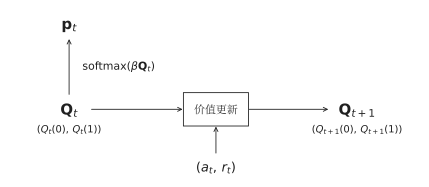

In [13]:
plot_rw_architecture()
show_svg(FIGURE_DIR / "rw_architecture.svg")

**图 2　RW 模型。** 当前价值状态产生选择概率，真实动作与奖励用于更新下一状态。每次更新只改变被选动作的价值。

In [14]:
class RWModel:
    """以两个选项的价值预测选择；alpha 与 iTemp 在所有 block 间共享。"""

    def __init__(self, alpha=0.5, iTemp=5.0):
        self.alpha = alpha
        self.iTemp = iTemp

    def choice_probabilities(self, values):
        """将两个价值转换为选择概率，返回 [P(a=0), P(a=1)]。"""
        values = np.asarray(values, dtype=float)
        # 减去最大值可以避免指数溢出，不改变 softmax 的结果。
        scores = self.iTemp * (values - values.max())
        weights = np.exp(scores)
        return weights / weights.sum()

    def update_values(self, values, action, reward):
        """只更新被选择的选项，并保留输入的旧价值。"""
        new_values = values.copy()
        prediction_error = reward - new_values[action]
        new_values[action] += self.alpha * prediction_error
        return new_values

    def predict_block(self, actions, rewards):
        """先预测当前选择，再读取当前动作与奖励；每个 block 从零开始。"""
        values = np.zeros(2, dtype=float)
        probabilities = []
        states = []
        for t in range(len(actions)):
            states.append(values.copy())
            probabilities.append(self.choice_probabilities(values))
            values = self.update_values(values, actions[t], rewards[t])

        return {
            "probabilities": np.array(probabilities),
            "states": np.array(states),
            "final_state": values.copy(),
        }

    def update_state(self, state, action, reward):
        """从给定价值出发更新一步，供动力学分析使用。"""
        values = np.asarray(state, dtype=float)
        return self.update_values(values, action, reward)

## 5. GRU 模型：隐藏状态与门控更新

GRU 用隐藏状态 $\mathbf h_t$ 概括此前的行为历史。本实验将隐藏维度设为 2，并通过线性读出层产生两个动作分数，再用 softmax 得到选择概率：

$$
\mathbf p_t=\operatorname{softmax}(W_{\mathrm{out}}\mathbf h_t+\mathbf b_{\mathrm{out}}).
$$

模型由 `nn.GRU(input_size=2, hidden_size=2)` 和 `nn.Linear(2, 2)` 组成，共有 42 个可训练参数。二维状态便于在平面上观察更新过程，但两个隐藏坐标没有预先指定的价值含义。

GRU 读取本次输入 $\mathbf x_t=(a_t,r_t)^\mathsf T$ 后，输出的是下一状态 $\mathbf h_{t+1}$。预测当前动作时，应使用读取该输入之前的 $\mathbf h_t$。因此，`GRUModel.forward` 在状态序列开头加入零初始状态，并移除最后一项，使状态与预测目标正确对应。

In [15]:
def plot_gru_architecture():
    """显示试次间时序，再用简洁的主路径与弧线展开 GRU 的内部计算。"""
    from matplotlib.path import Path as DrawingPath
    from matplotlib.patches import Circle

    with plt.rc_context({"mathtext.fontset": "stix", "svg.fonttype": "path"}):
        figure, label, arrow_between, operation = _structure_canvas(
            13.2, 9.6, figsize=(7.4, 5.4)
        )
        axis = figure.axes[0]
        ink = "#202020"

        def curve(start, control_1, control_2, end):
            """三次贝塞尔曲线只用于旁路，使主要计算路径仍保持清楚。"""
            path = DrawingPath(
                [start, control_1, control_2, end],
                [DrawingPath.MOVETO, DrawingPath.CURVE4,
                 DrawingPath.CURVE4, DrawingPath.CURVE4],
            )
            axis.add_patch(FancyArrowPatch(
                path=path, arrowstyle="->", mutation_scale=10,
                linewidth=0.85, color=ink, zorder=1,
            ))

        def junction(x, y):
            axis.add_patch(Circle((x, y), 0.030, facecolor=ink, edgecolor="none", zorder=3))

        def elementwise(x, y, symbol):
            axis.add_patch(Circle((x, y), 0.20, facecolor="white",
                                  edgecolor=ink, linewidth=0.8, zorder=3))
            if symbol == r"$\odot$":
                # 外圆和中心实心点共同组成逐元素乘号，避免再套一层圆圈。
                axis.add_patch(Circle((x, y), 0.045, facecolor=ink,
                                      edgecolor="none", zorder=4))
            else:
                label(x, y, symbol, size=13)

        # a：同一个 GRU 在相邻试次重复使用；每个 h 都是二维向量。
        label(0.22, 9.25, "a", size=12, ha="left")
        label(0.70, 9.25, figure_label("试次间的状态传递", "State across trials"), size=11, ha="left")
        state_y = 7.95
        for x, text in ((0.92, r"$\mathbf{h}_{t-1}$"),
                        (5.36, r"$\mathbf{h}_t$"),
                        (10.80, r"$\mathbf{h}_{t+1}$")):
            label(x, state_y, text, size=15)
        for x in (3.0, 8.0):
            operation(x, state_y, r"$\mathrm{GRU}_{\theta}$", width=1.24, height=0.65)
        arrow_between((1.56, state_y), (2.35, state_y))
        arrow_between((3.65, state_y), (4.94, state_y))
        arrow_between((5.79, state_y), (7.35, state_y))
        arrow_between((8.65, state_y), (10.16, state_y))
        label(3.0, 7.05, r"$\mathbf{x}_{t-1}$", size=13)
        label(8.0, 7.05, r"$\mathbf{x}_{t}=(a_t,r_t)$", size=13)
        arrow_between((3.0, 7.31), (3.0, 7.59))
        arrow_between((8.0, 7.31), (8.0, 7.59))
        label(5.36, 9.25, r"$\mathbf{p}_t$", size=15)
        arrow_between((5.36, 8.25), (5.36, 8.94))
        label(5.72, 8.71, figure_label("线性读出 → softmax", "Linear → softmax"), size=10, ha="left")

        # b：候选状态计算沿水平主路径展开；门控和保留路径从侧面汇入。
        label(0.22, 6.25, "b", size=12, ha="left")
        label(0.70, 6.25, figure_label("GRU 的内部计算", "GRU update"), size=11, ha="left")
        main_y = 3.35
        label(0.80, main_y, r"$\mathbf{h}_{t}$", size=15)
        arrow_between((1.19, main_y), (1.94, main_y))
        operation(2.90, main_y, r"$W_h\mathbf{h}_t+\mathbf{b}_h$", width=1.88, height=0.60)
        arrow_between((3.88, main_y), (4.42, main_y))
        elementwise(4.65, main_y, r"$\odot$")
        arrow_between((4.88, main_y), (6.12, main_y))
        elementwise(6.35, main_y, r"$+$")
        arrow_between((6.58, main_y), (7.22, main_y))
        operation(7.80, main_y, r"$\tanh$", width=1.06, height=0.60)
        arrow_between((8.36, main_y), (9.62, main_y))
        label(8.91, 2.94, r"$\tilde{\mathbf{h}}_{t+1}$", size=13)
        elementwise(9.85, main_y, r"$\odot$")

        # 旧状态沿上方支路保留，并由更新门决定其权重。
        junction(1.50, main_y)
        curve((1.50, main_y), (1.75, 6.0), (9.25, 6.3), (9.85, 5.08))
        elementwise(9.85, 4.85, r"$\odot$")

        # 门内直接显示矩阵乘法；两部分权重并列、偏置相加后合并书写。
        # 重置门仍在旧状态的矩阵乘法与加偏置之后相乘。
        operation(2.70, 1.80,
                  r"$\sigma\!\left(W_\rho\binom{\mathbf{x}_t}{\mathbf{h}_t}+\mathbf{b}_\rho\right)$",
                  width=3.50, height=0.80)
        label(2.70, 2.47, figure_label("重置门", "Reset gate"), size=10)
        curve((4.49, 1.80), (4.65, 1.80), (4.65, 2.47), (4.65, 3.12))
        label(4.86, 2.39, r"$\boldsymbol{\rho}_t$", size=13, ha="left")

        # x_t 紧邻矩阵乘法节点；输入支路不受重置门控制。
        label(6.35, 0.76, r"$\mathbf{x}_t$", size=15)
        arrow_between((6.35, 1.02), (6.35, 1.47))
        operation(6.35, 1.80, r"$W_x\mathbf{x}_t+\mathbf{b}_x$", width=1.88, height=0.60)
        arrow_between((6.35, 2.13), (6.35, 3.12))

        # 更新门为旧状态和候选状态分别赋予 z_t 与 1-z_t 的权重。
        operation(7.25, 4.85,
                  r"$\sigma\!\left(W_z\binom{\mathbf{x}_t}{\mathbf{h}_t}+\mathbf{b}_z\right)$",
                  width=3.50, height=0.80)
        label(7.25, 5.52, figure_label("更新门", "Update gate"), size=10)
        arrow_between((9.04, 4.85), (9.62, 4.85))
        label(9.40, 5.16, r"$\mathbf{z}_t$", size=12)
        junction(9.23, 4.85)
        curve((9.23, 4.85), (9.66, 4.85), (9.85, 4.12), (9.85, 3.58))
        label(8.95, 4.00, r"$1-\mathbf{z}_t$", size=12)

        # 旧状态与候选状态加权相加，得到下一试次的隐藏状态。
        curve((10.08, 4.85), (10.79, 4.85), (11.55, 4.70), (11.55, 4.33))
        curve((10.08, main_y), (10.79, main_y), (11.55, 3.50), (11.55, 3.87))
        elementwise(11.55, 4.10, r"$+$")
        arrow_between((11.78, 4.10), (12.27, 4.10))
        label(12.76, 4.10, r"$\mathbf{h}_{t+1}$", size=15)

        # 只在图内解释运算符；其余符号定义和公式由正文说明。
        label(9.30, 0.85, figure_label(r"$\odot$ 逐元素乘    $\oplus$ 逐元素加", r"$\odot$ multiply    $\oplus$ add"), size=10)
        save_figure(figure, "gru_architecture")

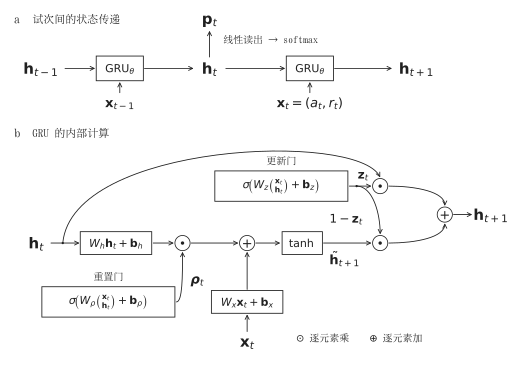

In [16]:
plot_gru_architecture()
show_svg(FIGURE_DIR / "gru_architecture.svg")

**图 3　GRU 模型。** 上图表示试次间的状态传递与选择读出，下图展开一次门控更新。$\odot$ 表示逐元素乘，圈内加号表示逐元素加。

In [17]:
class GRUModel(nn.Module):
    """输入为动作与奖励，以二维隐藏状态预测两个动作的分数。"""

    def __init__(self, hidden_dim=2):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.gru = nn.GRU(input_size=2, hidden_size=hidden_dim, batch_first=False)
        self.linear = nn.Linear(hidden_dim, 2)

    def forward(self, inputs):
        """输入 (T, B, 2)，返回预测分数及状态；保留参数梯度供训练使用。"""
        # B 个 block 各有独立的零初始状态，不在 block 之间传递记忆。
        h0 = torch.zeros(
            1, inputs.size(1), self.hidden_dim,
            dtype=inputs.dtype, device=inputs.device,
        )
        updated_states, final_state = self.gru(inputs, h0)

        # 当前预测只能使用此前的事件：在开头加入 h0，移去最后一个更新后状态。
        states = torch.cat([h0, updated_states[:-1]], dim=0)
        logits = self.linear(states)
        return {
            "logits": logits,
            "states": states,
            "final_state": final_state.squeeze(0),
        }

    def predict_block(self, actions, rewards):
        """评估单个 block，返回 NumPy 格式的选择概率与状态轨迹。"""
        parameter = next(self.parameters())
        inputs = np.stack([actions, rewards], axis=-1)
        inputs = torch.tensor(inputs, dtype=parameter.dtype, device=parameter.device)
        inputs = inputs.unsqueeze(1)  # (T, 1, 2)

        self.eval()
        with torch.no_grad():
            result = self(inputs)
            probabilities = torch.softmax(result["logits"], dim=-1)
        return {
            "probabilities": probabilities[:, 0].cpu().numpy(),
            "states": result["states"][:, 0].cpu().numpy(),
            "final_state": result["final_state"][0].cpu().numpy(),
        }

    def update_state(self, state, action, reward):
        """从指定隐藏状态读取一次事件，不执行 block 的零初始化。"""
        parameter = next(self.parameters())
        hidden = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)
        hidden = hidden.reshape(1, 1, self.hidden_dim)
        inputs = torch.tensor(
            [[[action, reward]]], dtype=parameter.dtype, device=parameter.device,
        )
        self.eval()
        with torch.no_grad():
            _, next_hidden = self.gru(inputs, hidden)
        return next_hidden[0, 0].cpu().numpy()

    def choice_probabilities(self, state):
        """从给定隐藏状态读出两个动作的概率，不更新状态。"""
        parameter = next(self.parameters())
        hidden = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)
        with torch.no_grad():
            logits = self.linear(hidden)
            probabilities = torch.softmax(logits, dim=-1)
        return probabilities.cpu().numpy()

GRU 通过重置门与更新门调节历史信息。为说明内部运算，将当前输入和旧状态分别经过矩阵乘法与偏置得到的结果记为 $\mathbf i$ 和 $\mathbf g$。两者各包含重置门、更新门和候选状态三个分支。门值的计算为

$$
\boldsymbol\rho_t=\sigma(\mathbf i_\rho+\mathbf g_\rho),\qquad
\mathbf z_t=\sigma(\mathbf i_z+\mathbf g_z),
$$

候选状态与下一状态为

$$
\widetilde{\mathbf h}_{t+1}=\tanh(\mathbf i_n+\boldsymbol\rho_t\odot\mathbf g_n),
$$
$$
\mathbf h_{t+1}=\mathbf z_t\odot\mathbf h_t+(1-\mathbf z_t)\odot\widetilde{\mathbf h}_{t+1}.
$$

$\sigma$ 为 sigmoid 函数，将门值限制在 0 与 1 之间；$\odot$ 表示逐元素乘法。重置门调节变换后的旧状态对候选状态的贡献，更新门决定旧状态与候选状态的混合比例。两个门均依赖当前输入和旧状态，因此相同反馈可以在不同历史状态下产生不同更新。

以下计算采用 PyTorch 的 GRU 定义：重置门作用于旧状态的矩阵变换与偏置之和。参数按重置门、更新门、候选状态的顺序排列，`chunk(3)` 将相应分支分开。

In [18]:
def gru_update_state(model, state, action, reward):
    """根据重置门、更新门和候选状态计算一次状态更新。"""
    parameter = next(model.parameters())
    x = torch.tensor([action, reward], dtype=parameter.dtype, device=parameter.device)
    h = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)

    with torch.no_grad():
        input_parts = (
            model.gru.weight_ih_l0 @ x + model.gru.bias_ih_l0
        )
        hidden_parts = (
            model.gru.weight_hh_l0 @ h + model.gru.bias_hh_l0
        )
        input_reset, input_update, input_candidate = input_parts.chunk(3)
        hidden_reset, hidden_update, hidden_candidate = hidden_parts.chunk(3)

        reset_gate = torch.sigmoid(input_reset + hidden_reset)
        update_gate = torch.sigmoid(input_update + hidden_update)
        candidate = torch.tanh(input_candidate + reset_gate * hidden_candidate)
        next_state = update_gate * h + (1 - update_gate) * candidate

    return next_state.cpu().numpy()

## 6. 参数估计

两种模型均以提高真实选择的预测概率为目标。RW 在训练集上估计 $\alpha$ 和 $\beta$；GRU 通过反向传播更新权重，并保留验证集负对数似然最低时的参数。测试集用于拟合结束后的评价。

应区分参数估计与任务中的状态变化：训练时，GRU 的权重随优化过程改变；分析行为时，权重固定，隐藏状态随动作与奖励逐次更新。代码中的 `LEARNING_RATE` 控制优化器的步长，与 RW 学习率 $\alpha$ 的行为含义不同。

`RWModel` 与 `GRUModel` 封装了前述更新规则，`fit_rw` 与 `fit_gru` 完成参数估计。以下给出两种优化过程的完整实现，并从初始参数开始拟合。训练 NLL 记录每轮参数更新前的损失，验证 NLL 记录该轮更新后的损失；训练结束时恢复验证 NLL 最低的权重。

负对数似然取真实动作对应概率的负对数。为避免数值下溢，对概率设置很小的正下界。`evaluate` 按试次数加权汇总各 block 的指标，保持各 block 的状态独立初始化。

In [19]:
def negative_log_likelihood(probabilities, actions):
    """真实选择对应的平均负对数似然，使用自然对数。"""
    true_probabilities = probabilities[np.arange(len(actions)), actions]
    true_probabilities = np.clip(true_probabilities, 1e-10, None)
    return -np.mean(np.log(true_probabilities))


def accuracy(probabilities, actions):
    """预测动作与猴子实际动作相同的比例；概率相同时选动作 0。"""
    predicted_actions = np.argmax(probabilities, axis=1)
    return np.mean(predicted_actions == actions)


def evaluate(model, blocks):
    """独立预测各 block，再按试次数加权汇总指标。"""
    total_nll = []
    total_correct = []
    total_trials = 0
    for block in blocks:
        actions = block["actions"]
        prediction = model.predict_block(actions, block["rewards"])
        probabilities = prediction["probabilities"]
        n_trials = len(actions)
        total_nll.append(negative_log_likelihood(probabilities, actions) * n_trials)
        total_correct.append(accuracy(probabilities, actions) * n_trials)
        total_trials += n_trials
    return {
        "n_trials": total_trials,
        "nll": float(np.sum(total_nll) / total_trials),
        "accuracy": float(np.sum(total_correct) / total_trials),
    }

### RW 参数估计

优化变量为学习率和逆温度。每次计算目标函数时，各训练 block 均从零价值开始。

In [20]:
def fit_rw(model, train_blocks):
    """最小化训练集平均负对数似然，将拟合后的 alpha、iTemp 写入模型。"""
    def objective(parameters):
        model.alpha, model.iTemp = parameters
        total_nll = 0.0
        total_trials = 0
        for block in train_blocks:
            actions = block["actions"]
            probabilities = model.predict_block(actions, block["rewards"])["probabilities"]
            n_trials = len(actions)
            total_nll += negative_log_likelihood(probabilities, actions) * n_trials
            total_trials += n_trials
        return total_nll / total_trials

    result = minimize(
        objective,
        x0=[0.5, 1.0],
        bounds=[(0, 1), (1e-8, None)],
        method="L-BFGS-B",
    )
    if not result.success:
        raise RuntimeError(f"RW 参数优化失败：{result.message}")
    model.alpha, model.iTemp = result.x

### GRU 参数估计

每轮将全部训练 block 的预测损失反向传播一次。验证损失连续若干轮未改善时停止训练，`PATIENCE` 指定这一轮数。

In [21]:
def fit_gru(
    model, train_blocks, validation_blocks,
    learning_rate=0.005, max_epochs=1000, patience=100,
):
    """使用训练集更新权重，以验证集选择停止时机，恢复最佳验证权重。"""
    train_inputs, train_targets = prepare_batch(train_blocks, model)
    validation_inputs, validation_targets = prepare_batch(validation_blocks, model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0)
    criterion = nn.CrossEntropyLoss()
    best_validation_loss = float("inf")
    best_state = None
    epochs_without_improvement = 0
    history = {
        "epoch": [],
        "train_nll": [],
        "validation_nll": [],
        "best_epoch": 0,
    }

    for epoch in range(1, max_epochs + 1):
        # 一轮使用所有训练 block；交叉熵在全部试次上取平均。
        model.train()
        optimizer.zero_grad()
        logits = model(train_inputs)["logits"]
        train_loss = criterion(logits.reshape(-1, 2), train_targets.reshape(-1))
        train_loss.backward()
        optimizer.step()

        # 验证集只参与停止时机的选择，不用于计算参数更新的梯度。
        model.eval()
        with torch.no_grad():
            logits = model(validation_inputs)["logits"]
            validation_loss = criterion(
                logits.reshape(-1, 2), validation_targets.reshape(-1),
            ).item()

        history["epoch"].append(epoch)
        history["train_nll"].append(train_loss.item())
        history["validation_nll"].append(validation_loss)
        if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            history["best_epoch"] = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 100 == 0:
            print(
                f"第 {epoch:4d} 轮：训练 NLL = {train_loss.item():.4f}，"
                f"验证 NLL = {validation_loss:.4f}"
            )
        if epochs_without_improvement >= patience:
            break

    if best_state is None:
        raise RuntimeError("未得到有效的验证损失，请检查数据和训练参数。")
    model.load_state_dict(best_state)
    print(f"训练结束：恢复第 {history['best_epoch']} 轮的权重，验证 NLL = {best_validation_loss:.4f}。")
    return history

In [22]:
rw_model = RWModel()
print("估计 RW 参数……", flush=True)
fit_rw(rw_model, train_blocks)

# 固定初始化种子；模型与输入均使用 CPU。
torch.manual_seed(SEED)
gru_model = GRUModel(hidden_dim=HIDDEN_DIM)
print("估计 GRU 参数……", flush=True)
history = fit_gru(
    gru_model,
    train_blocks,
    validation_blocks,
    learning_rate=LEARNING_RATE,
    max_epochs=MAX_EPOCHS,
    patience=PATIENCE,
)
models = {"RW": rw_model, "GRU": gru_model}
print(f"RW：alpha = {rw_model.alpha:.6f}，iTemp = {rw_model.iTemp:.6f}")
print("GRU 参数数量：", sum(parameter.numel() for parameter in gru_model.parameters()))
print("验证 NLL 最低的训练轮次：", history["best_epoch"])

估计 RW 参数……


估计 GRU 参数……


第    1 轮：训练 NLL = 0.7675，验证 NLL = 0.8038


第  100 轮：训练 NLL = 0.5473，验证 NLL = 0.4872


第  200 轮：训练 NLL = 0.4428，验证 NLL = 0.3355


第  300 轮：训练 NLL = 0.4182，验证 NLL = 0.3126


第  400 轮：训练 NLL = 0.4023，验证 NLL = 0.3015


第  500 轮：训练 NLL = 0.3964，验证 NLL = 0.2951


第  600 轮：训练 NLL = 0.3938，验证 NLL = 0.2945
训练结束：恢复第 571 轮的权重，验证 NLL = 0.2943。
RW：alpha = 0.445283，iTemp = 3.387289
GRU 参数数量： 42
验证 NLL 最低的训练轮次： 571


## 7. 选择预测与状态轨迹

参数确定后，分别计算各测试 block 的逐试次选择概率和内部状态。`states[t]` 表示第 $t$ 次反馈前的状态，`final_state` 保存最后一次反馈后的状态。一个包含 $T$ 次试次的 block 因而对应 $T$ 组预测与 $T+1$ 个状态位置。

这些记录同时用于预测评价和动力学分析。状态更新与预测时序的检查列于附录。

In [23]:
def collect_predictions(models, blocks):
    """保存各 block 的真实事件、预测概率和完整状态轨迹。"""
    records = []
    for block in blocks:
        record = block.copy()
        record["models"] = {}
        for model_name, model in models.items():
            record["models"][model_name] = model.predict_block(
                block["actions"], block["rewards"],
            )
        records.append(record)
    return records


def summarize_model_comparison(records):
    """在同一只猴子的全部测试试次上比较 RW 与 GRU。"""
    actions = np.concatenate([record["actions"] for record in records])
    comparison = {
        "animal_name": records[0]["animal_name"],
        "n_blocks": len(records),
        "n_sessions": len({record["session_name"] for record in records}),
        "n_trials": len(actions),
        "models": {},
    }
    for model_name in ("RW", "GRU"):
        block_probabilities = []
        for record in records:
            probabilities = record["models"][model_name]["probabilities"]
            block_probabilities.append(probabilities)
        # 此处拼接已计算的概率；各 block 的状态始终独立演化。
        probabilities = np.concatenate(block_probabilities)
        comparison["models"][model_name] = {
            "nll": float(negative_log_likelihood(probabilities, actions)),
            "accuracy": float(accuracy(probabilities, actions)),
        }
    return comparison

In [24]:
records = collect_predictions(models, test_blocks)
n_test_trials = sum(len(record["actions"]) for record in records)
show_table(
    ["模型", "选择概率形状", "反馈前状态形状", "末状态形状"],
    [
        [name, prediction["probabilities"].shape, prediction["states"].shape, prediction["final_state"].shape]
        for name, prediction in records[0]["models"].items()
    ],
)
print(f"测试记录：{len(records)} 个 block，{n_test_trials} 次试次。")

| 模型 | 选择概率形状 | 反馈前状态形状 | 末状态形状 |
| --- | --- | --- | --- |
| RW | (60, 2) | (60, 2) | (2,) |
| GRU | (60, 2) | (60, 2) | (2,) |

测试记录：9 个 block，540 次试次。


## 8. 测试集上的预测表现

预测评价使用每试次平均负对数似然（negative log-likelihood，NLL）：

$$
\mathrm{NLL}=-\frac{1}{N}\sum_{t=1}^{N}\ln p_t(a_t),
$$

其中，$N$ 为测试试次数，$p_t(a_t)$ 为模型赋予真实选择的概率。NLL 越低，表示模型整体上为真实选择分配的概率越高。

选择准确率统计预测概率最大的动作与真实动作相同的比例。与准确率相比，NLL 还反映预测的确信程度。两个指标均按测试试次汇总，用于比较同一组行为数据上的预测表现。

In [25]:
def plot_model_comparison(comparison: dict, output_dir: str | Path) -> None:
    """比较同一测试集的预测；样本信息和结论范围放在独立图注中。"""
    model_names = ["RW", "GRU"]
    nll_values = [comparison["models"][name]["nll"] for name in model_names]
    accuracy_values = [
        100 * comparison["models"][name]["accuracy"] for name in model_names
    ]
    colors = [MODEL_COLORS[name] for name in model_names]

    with _publication_style():
        figure, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
        figure.subplots_adjust(
            left=0.09, right=0.985, bottom=0.18, top=0.90, wspace=0.45
        )
        for panel, axis, values in zip("ab", axes, (nll_values, accuracy_values)):
            bars = axis.bar(model_names, values, width=0.55, color=colors)
            axis.margins(x=0.26)
            axis.text(
                -0.20,
                1.04,
                panel,
                transform=axis.transAxes,
                fontsize=10,
                fontweight="bold",
                va="bottom",
            )
            for bar, value in zip(bars, values):
                number = f"{value:.3f}" if axis is axes[0] else f"{value:.1f}"
                axis.annotate(
                    number,
                    xy=(bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

        # 柱状图保留零基线，不借截断纵轴放大模型之间的差异。
        axes[0].set_ylim(0, max(max(nll_values) * 1.22, 0.1))
        axes[0].yaxis.set_major_locator(MaxNLocator(nbins=5))
        axes[0].set_ylabel("Test NLL")
        axes[1].set_ylim(0, 100)
        axes[1].set_yticks(np.arange(0, 101, 20))
        axes[1].set_ylabel("Accuracy (%)")
        _save(figure, output_dir, "model_comparison")

| 模型 | 测试试次数 | 平均 NLL | 选择准确率 |
| --- | --- | --- | --- |
| RW | 540 | 0.400852 | 82.22% |
| GRU | 540 | 0.367249 | 84.07% |

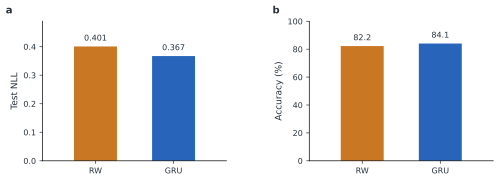

In [26]:
metrics = {}
for model_name, model in models.items():
    metrics[model_name] = evaluate(model, test_blocks)

show_table(
    ["模型", "测试试次数", "平均 NLL", "选择准确率"],
    [
        [name, score["n_trials"], f"{score['nll']:.6f}", f"{score['accuracy']:.2%}"]
        for name, score in metrics.items()
    ],
)
comparison = summarize_model_comparison(records)
plot_model_comparison(comparison, FIGURE_DIR)
show_svg(FIGURE_DIR / "model_comparison.svg")

**图 4　测试集预测表现。** 两个模型评价同一组测试试次。平均 NLL 越低，表示模型整体上赋予真实选择的概率越高；选择准确率越高，表示预测正确的试次比例越大。

## 9. 条件状态动力学

预测表现说明模型能否描述行为，状态动力学进一步揭示这种预测如何由内部更新产生。固定拟合后的参数，将一次更新写为

$$
\mathbf s_{t+1}=F_{a,r}(\mathbf s_t),\qquad
\Delta\mathbf s=F_{a,r}(\mathbf s_t)-\mathbf s_t.
$$

RW 的状态为 $(Q(0),Q(1))$，GRU 的状态为 $(h_1,h_2)$。动作和奖励均取 0 或 1，因此共有四种输入条件。将全部测试 block 中属于同一条件的更新汇总，可以观察相同反馈在不同起始状态下的作用。

状态差分在各 block 内分别计算。末状态用于补全最后一次更新，不同 block 之间的初始化过程不计为学习更新。

In [27]:
# 分别计算各 block 内的状态差，再汇总测试事件。
observed_updates = {}
for model_name in models:
    changes_by_block = []
    for record in records:
        prediction = record["models"][model_name]
        complete_states = np.vstack([
            prediction["states"],
            prediction["final_state"],
        ])
        changes = complete_states[1:] - complete_states[:-1]
        changes_by_block.append(changes)
    observed_updates[model_name] = np.concatenate(changes_by_block)
    print(model_name, "状态更新数组形状：", observed_updates[model_name].shape)

event_counts = Counter()
for record in records:
    event_counts.update(zip(record["actions"].tolist(), record["rewards"].tolist()))
show_table(
    ["动作 a", "奖励 r", "整个测试集的事件数"],
    [[action, reward, event_counts[(action, reward)]] for action, reward in [(0, 0), (0, 1), (1, 0), (1, 1)]],
)

RW 状态更新数组形状： (540, 2)
GRU 状态更新数组形状： (540, 2)


| 动作 a | 奖励 r | 整个测试集的事件数 |
| --- | --- | --- |
| 0 | 0 | 101 |
| 0 | 1 | 188 |
| 1 | 0 | 116 |
| 1 | 1 | 135 |

`get_readout` 给出动作 0 相对动作 1 的分数差，用于确定等概率边界。`compute_vector_field` 在状态网格上计算四种输入的条件更新；`compute_model_dynamics` 将这些更新与全部测试 block 的实际事件相对应。

In [28]:
def get_readout(model):
    """返回两个动作分数之差中的权重与偏置：d(s) = w · s + b。

    d(s) = 0 是两个动作等概率的边界；d(s) > 0 时，动作 0 的概率更高。
    """
    if isinstance(model, RWModel):
        readout_vector = np.array([model.iTemp, -model.iTemp], dtype=float)
        readout_bias = 0.0
    else:
        weights = model.linear.weight.detach().cpu().numpy()
        biases = model.linear.bias.detach().cpu().numpy()
        readout_vector = np.asarray(weights[0] - weights[1], dtype=float)
        readout_bias = float(biases[0] - biases[1])
    return readout_vector, readout_bias

In [29]:
def compute_vector_field(model, states, grid_size=41, state_limits=None):
    """在状态网格上分别计算四种动作与奖励组合的一步更新。

    states 包含测试集中实际出现的状态，只用于确定网格范围。
    网格点未必被实际访问；背景颜色表示假设处于该点时的更新幅度。
    """
    states = np.asarray(states, dtype=float)
    readout_vector, readout_bias = get_readout(model)

    # 从全部状态的范围出发留出少量边距，再限制在模型的有效状态区间内。
    lower = states.min(axis=0)
    upper = states.max(axis=0)
    padding = np.maximum((upper - lower) * 0.12, 0.05)
    lower = lower - padding
    upper = upper + padding
    if state_limits is not None:
        lower = np.maximum(lower, state_limits[0])
        upper = np.minimum(upper, state_limits[1])

    x_values = np.linspace(lower[0], upper[0], grid_size)
    y_values = np.linspace(lower[1], upper[1], grid_size)
    x_grid, y_grid = np.meshgrid(x_values, y_values)
    points = np.column_stack([x_grid.ravel(), y_grid.ravel()])

    # 选择概率可用于其他分析；本实验的动力学背景使用下方计算的更新幅度。
    probabilities = []
    for state in points:
        probabilities.append(model.choice_probabilities(state)[0])
    probability_grid = np.asarray(probabilities).reshape(x_grid.shape)

    conditions = []
    for action in (0, 1):
        for reward in (0, 1):
            changes = []
            for state in points:
                next_state = model.update_state(state, action, reward)
                changes.append(next_state - state)
            changes = np.asarray(changes)

            # 更新向量给出方向，欧氏长度给出背景颜色及等值线的数值。
            speed = np.linalg.norm(changes, axis=1).reshape(x_grid.shape)
            conditions.append(
                {
                    "action": action,
                    "reward": reward,
                    "dx": changes[:, 0].reshape(x_grid.shape),
                    "dy": changes[:, 1].reshape(y_grid.shape),
                    "speed": speed,
                    "observed_states": np.empty((0, 2)),
                    "observed_changes": np.empty((0, 2)),
                }
            )

    # 同一模型的四个面板共享色标；不同模型的坐标单位不同，分别设定色标。
    speed_max = max(float(condition["speed"].max()) for condition in conditions)
    return {
        "x": x_grid,
        "y": y_grid,
        "probability": probability_grid,
        "conditions": conditions,
        "observed_states": states.copy(),
        "has_observed_events": False,
        "speed_max": speed_max,
        "readout_vector": readout_vector,
        "readout_bias": readout_bias,
    }

In [30]:
def compute_model_dynamics(
    model,
    records,
    model_name,
    grid_size=41,
    state_limits=None,
    max_arrows_per_condition=None,
    sample_seed=0,
):
    """固定模型参数，汇总整个测试集的状态更新。

    每个 block 内先计算相邻状态的差，再将不同 block 的结果合并。
    默认保留全部事件；如设置箭头数量上限，抽样仅影响箭头显示。
    """
    all_states = []
    update_starts = []
    update_changes = []
    all_actions = []
    all_rewards = []
    source_blocks = []
    for record in records:
        prediction = record["models"][model_name]
        states = np.asarray(prediction["states"], dtype=float)
        final_state = np.asarray(prediction["final_state"], dtype=float)
        actions = np.asarray(record["actions"])
        rewards = np.asarray(record["rewards"])

        # states[t] 是反馈前的状态；补入 final_state 才能包含最后一次更新。
        # 不对拼接后的多 block 轨迹求差，避免把 block 间的重置误当成学习。
        complete_states = np.vstack([states, final_state])
        changes = complete_states[1:] - complete_states[:-1]
        all_states.append(complete_states)
        update_starts.append(states)
        update_changes.append(changes)
        all_actions.append(actions)
        all_rewards.append(rewards)
        source_blocks.append(
            {
                "animal_name": record["animal_name"],
                "session_name": record["session_name"],
                "block_order": record["block_order"],
                "block_type": record["block_type"],
            }
        )

    # 全部实际状态共同确定网格范围，其中包含每个 block 的最终状态。
    field = compute_vector_field(
        model,
        np.concatenate(all_states),
        grid_size=grid_size,
        state_limits=state_limits,
    )
    starts = np.concatenate(update_starts)
    changes = np.concatenate(update_changes)
    actions = np.concatenate(all_actions)
    rewards = np.concatenate(all_rewards)

    rng = np.random.default_rng(sample_seed)
    for condition in field["conditions"]:
        selected = (actions == condition["action"]) & (rewards == condition["reward"])
        event_indices = np.flatnonzero(selected)
        n_observed = len(event_indices)
        if max_arrows_per_condition is not None and n_observed > max_arrows_per_condition:
            event_indices = np.sort(
                rng.choice(event_indices, size=max_arrows_per_condition, replace=False)
            )

        # 同一索引同时提取更新起点和变化量；相同种子使两个模型抽到相同事件。
        condition["observed_states"] = starts[event_indices].copy()
        condition["observed_changes"] = changes[event_indices].copy()
        condition["event_indices"] = event_indices
        condition["n_observed"] = n_observed
        condition["n_displayed"] = len(event_indices)

    field["has_observed_events"] = True
    field["source_blocks"] = source_blocks
    field["n_trials"] = len(actions)
    field["max_arrows_per_condition"] = max_arrows_per_condition
    field["sample_seed"] = sample_seed
    return field

In [31]:
def _decision_boundary_segment(
    readout_vector: np.ndarray,
    readout_bias: float,
    x_limits: tuple[float, float],
    y_limits: tuple[float, float],
) -> np.ndarray:
    """求 w·state+b=0 与可视矩形的交点，不把边界误写成经过原点。

    直接求四条边上的交点，也适用于水平或竖直的决策边界。
    如果读出权重为零，或边界没有穿过当前区域，就不画这条线。
    """
    vector_length = np.linalg.norm(readout_vector)
    if vector_length == 0:
        return np.empty((0, 2))
    normal = readout_vector / vector_length
    offset = readout_bias / vector_length
    x_min, x_max = x_limits
    y_min, y_max = y_limits
    tolerance = 1e-10 * max(x_max - x_min, y_max - y_min, 1.0)
    candidates = []

    if abs(normal[1]) > 1e-12:
        for x_value in x_limits:
            y_value = -(normal[0] * x_value + offset) / normal[1]
            if y_min - tolerance <= y_value <= y_max + tolerance:
                candidates.append([x_value, float(np.clip(y_value, y_min, y_max))])
    if abs(normal[0]) > 1e-12:
        for y_value in y_limits:
            x_value = -(normal[1] * y_value + offset) / normal[0]
            if x_min - tolerance <= x_value <= x_max + tolerance:
                candidates.append([float(np.clip(x_value, x_min, x_max)), y_value])

    # 经过矩形角点时，同一个交点可能被两条边同时找到。
    unique_points = []
    for candidate in candidates:
        already_found = any(
            np.linalg.norm(np.asarray(candidate) - point) <= tolerance
            for point in unique_points
        )
        if not already_found:
            unique_points.append(np.asarray(candidate))
    if len(unique_points) < 2:
        return np.empty((0, 2))
    return np.asarray(unique_points[:2])


def plot_dynamics_comparison(fields: dict, output_dir: str | Path) -> None:
    """汇总测试集，在同一张图中比较 RW 与 GRU 的四种条件动力学。

    每一行对应一套已经拟合好的模型，每一列固定一种动作和奖励组合。
    背景在状态网格上计算；黑箭头使用传入的全部真实事件，不在绘图时抽样。
    同一模型共享坐标和色标，但 Q 与 h 的单位不同，因此两行独立标色。
    数据范围、读出边界和图例含义在独立图注中解释，不写成长段图内文字。
    """
    model_names = ("RW", "GRU")
    event_order = ((0, 0), (0, 1), (1, 0), (1, 1))
    # 直接调浅颜色，避免半透明网格的小三角形重叠形成额外纹理。
    base_colors = matplotlib.colormaps["viridis"](np.linspace(0, 1, 256))[:, :3]
    pale_colors = 0.73 + 0.27 * base_colors
    pale_colormap = matplotlib.colors.ListedColormap(pale_colors)

    with _publication_style():
        figure = plt.figure(figsize=(8.0, 4.2))
        layout = figure.add_gridspec(
            2,
            5,
            width_ratios=[1, 1, 1, 1, 0.07],
            left=0.10,
            right=0.90,
            bottom=0.12,
            top=0.91,
            wspace=0.30,
            hspace=0.40,
        )

        for row_index, model_name in enumerate(model_names):
            field = fields[model_name]
            grid_x = np.asarray(field["x"])
            grid_y = np.asarray(field["y"])
            all_states = np.asarray(field["observed_states"])
            conditions = {
                (condition["action"], condition["reward"]): condition
                for condition in field["conditions"]
            }

            # 全部访问状态包括每个 block 的末状态。坐标范围不由箭头抽样决定。
            x_min = min(float(grid_x.min()), float(all_states[:, 0].min()))
            x_max = max(float(grid_x.max()), float(all_states[:, 0].max()))
            y_min = min(float(grid_y.min()), float(all_states[:, 1].min()))
            y_max = max(float(grid_y.max()), float(all_states[:, 1].max()))
            x_margin = 0.02 * max(x_max - x_min, 0.1)
            y_margin = 0.02 * max(y_max - y_min, 0.1)
            x_limits = (x_min - x_margin, x_max + x_margin)
            y_limits = (y_min - y_margin, y_max + y_margin)

            speed_max = float(field["speed_max"])
            color_max = speed_max if speed_max > 0 else 1.0
            # 四个条件统一使用 20 个等值层级，便于看清较小幅度区域的结构。
            contour_levels = np.linspace(0, color_max, 22)[1:-1]
            boundary = _decision_boundary_segment(
                np.asarray(field["readout_vector"]),
                float(field["readout_bias"]),
                x_limits,
                y_limits,
            )
            row_axes = []

            for column_index, event in enumerate(event_order):
                axis = figure.add_subplot(layout[row_index, column_index])
                row_axes.append(axis)
                condition = conditions[event]
                speed = np.asarray(condition["speed"])
                # 用 256 个细色阶近似连续填色，保留纯矢量且避免大量 SVG 渐变。
                # 数值网格和色标范围不变；关闭色阶边缘抗锯齿，避免可见白缝。
                background = axis.contourf(
                    grid_x,
                    grid_y,
                    speed,
                    levels=np.linspace(0, color_max, 257),
                    cmap=pale_colormap,
                    vmin=0,
                    vmax=color_max,
                    antialiased=False,
                )
                # 细线连接更新幅度相同的起点；它们不是连续的状态轨迹。
                visible_levels = contour_levels[
                    (contour_levels > speed.min()) & (contour_levels < speed.max())
                ]
                if len(visible_levels) > 0:
                    axis.contour(
                        grid_x,
                        grid_y,
                        speed,
                        levels=visible_levels,
                        colors="#526064",
                        linewidths=0.35,
                        alpha=0.45,
                    )

                starts = np.asarray(condition["observed_states"]).reshape(-1, 2)
                changes = np.asarray(condition["observed_changes"]).reshape(-1, 2)
                if len(starts) > 0:
                    # 保留实际一步位移，不归一化或放大，也不连接不同 block。
                    axis.quiver(
                        starts[:, 0],
                        starts[:, 1],
                        changes[:, 0],
                        changes[:, 1],
                        angles="xy",
                        scale_units="xy",
                        scale=1,
                        color="black",
                        width=0.0040,
                        headwidth=4.0,
                        headlength=5.0,
                        headaxislength=4.5,
                        minlength=0,
                        alpha=0.58,
                        zorder=3,
                    )
                else:
                    axis.text(
                        0.5,
                        0.07,
                        r"$n=0$",
                        transform=axis.transAxes,
                        ha="center",
                        fontsize=8,
                    )

                # 只保留等概率边界；省去额外的读出方向箭头，避免混淆两种箭头。
                if len(boundary) == 2:
                    axis.plot(
                        boundary[:, 0],
                        boundary[:, 1],
                        color="#d97706",
                        linestyle=(0, (4, 3)),
                        linewidth=0.9,
                        zorder=4,
                    )

                axis.set_xlim(x_limits)
                axis.set_ylim(y_limits)
                axis.set_aspect("equal", adjustable="box")
                axis.xaxis.set_major_locator(MaxNLocator(nbins=3))
                axis.yaxis.set_major_locator(MaxNLocator(nbins=3))
                axis.set_xlabel(
                    r"$Q_0$" if model_name == "RW" else r"$h_1$", labelpad=2
                )
                if column_index == 0:
                    axis.set_ylabel(
                        r"$Q_1$" if model_name == "RW" else r"$h_2$", labelpad=2
                    )
                else:
                    axis.tick_params(axis="y", labelleft=False)
                if row_index == 0:
                    action, reward = event
                    axis.set_title(rf"$(a_t,r_t)=({action},{reward})$", pad=13)
                panel_letter = chr(
                    ord("a") + row_index * len(event_order) + column_index
                )
                axis.text(
                    0.02,
                    1.035,
                    panel_letter,
                    transform=axis.transAxes,
                    fontweight="bold",
                    fontsize=9,
                    va="bottom",
                )

            # 每行各用一个色标；不同模型的颜色不能用来比较学习率。
            colorbar_axis = figure.add_subplot(layout[row_index, 4])
            colorbar = figure.colorbar(background, cax=colorbar_axis)
            colorbar.set_label(
                r"$\|\Delta Q\|_2$" if model_name == "RW" else r"$\|\Delta h\|_2$",
                labelpad=5,
            )
            if speed_max == 0:
                colorbar.set_ticks([0])
            else:
                colorbar.locator = MaxNLocator(nbins=3)
                colorbar.update_ticks()
            colorbar.outline.set_linewidth(0.5)

            # 行名只出现一次；其余解释由外部图注承担。
            first_position = row_axes[0].get_position()
            colorbar_position = colorbar_axis.get_position()
            colorbar_axis.set_position(
                [
                    colorbar_position.x0,
                    first_position.y0,
                    colorbar_position.width,
                    first_position.height,
                ]
            )
            figure.text(
                0.015,
                (first_position.y0 + first_position.y1) / 2,
                model_name,
                rotation=90,
                ha="center",
                va="center",
                fontsize=10,
                fontweight="bold",
            )

        _save(figure, output_dir, "dynamics_comparison")

In [32]:
fields = {}
for model_name, model in models.items():
    state_limits = (0.0, 1.0) if model_name == "RW" else (-1.0, 1.0)
    fields[model_name] = compute_model_dynamics(
        model=model,
        records=records,
        model_name=model_name,
        grid_size=GRID_SIZE,
        state_limits=state_limits,
        max_arrows_per_condition=MAX_ARROWS_PER_CONDITION,
        sample_seed=DYNAMICS_SAMPLE_SEED,
    )
    field = fields[model_name]

plot_dynamics_comparison(fields, FIGURE_DIR)
show_svg(FIGURE_DIR / "dynamics_comparison.svg")

**图 5　整个测试集的条件状态动力学。** 上排为 RW，下排为 GRU，四列对应四种动作与奖励组合。黑箭头为实际反馈驱动的更新，背景与细等值线表示更新幅度，橙色虚线为两个动作的等概率边界。

每个面板固定一种动作与奖励条件。黑箭头表示真实测试历史驱动的模型更新，箭头起点和终点分别对应反馈前后的状态。背景颜色与细等值线表示假设状态下的更新幅度 $\|F_{a,r}(\mathbf s)-\mathbf s\|$。等值线连接幅度相同的位置，并不表示随时间发展的轨迹；背景网格也不意味着所有位置均被实际访问。

橙色虚线表示两个动作等概率的状态。RW 的边界为 $Q(0)=Q(1)$，GRU 的边界由拟合后的线性读出参数决定。状态相对边界的移动有助于解释选择偏好的变化。

同一模型的四个面板共用幅度色标。由于 Q 值与 GRU 隐藏状态的坐标单位不同，跨模型比较时应考察选择概率的变化，而不直接依据颜色或箭头长度判断学习速度。

## 10. 结果分析与讨论

首先比较两个模型的测试 NLL 和选择准确率，再结合动力学图考察其更新规则。RW 的每次反馈仅改变被选动作的价值，更新方向沿相应坐标轴；GRU 的更新可以同时改变两个隐藏坐标，其方向和幅度由当前状态与输入共同决定。GRU 的隐藏坐标不直接等同于两个动作价值。

若 GRU 的测试 NLL 较低，说明它在本次划分中比所用 RW 基线更好地描述了选择。动力学图提供了进一步分析这种差异的线索，但预测优势本身尚不足以确定动物采用了何种机制。

本实验在同一只猴子的既有 session 中留出测试 block。对新 session、新个体以及其他经典模型的比较，需要相应的独立检验。由网络更新提出的认知解释，也需要通过后续模型比较加以检验。

In [33]:
rw_score = metrics["RW"]
gru_score = metrics["GRU"]
print(f"RW：NLL = {rw_score['nll']:.4f}，选择准确率 = {rw_score['accuracy']:.2%}")
print(f"GRU：NLL = {gru_score['nll']:.4f}，选择准确率 = {gru_score['accuracy']:.2%}")
print(f"NLL 差值（RW − GRU）：{rw_score['nll'] - gru_score['nll']:.4f}")
print(f"准确率差值（GRU − RW）：{100 * (gru_score['accuracy'] - rw_score['accuracy']):.2f} 个百分点")

RW：NLL = 0.4009，选择准确率 = 82.22%
GRU：NLL = 0.3672，选择准确率 = 84.07%
NLL 差值（RW − GRU）：0.0336
准确率差值（GRU − RW）：1.85 个百分点


### 保存实验结果

以下保存参数、集合划分、测试指标与训练记录，并将逐试次预测单独写入文件。图片已保存为 SVG。再次运行会更新相同输出目录；保留另一组实验结果时，可修改 `OUTPUT_DIR`。

In [34]:
def json_value(value):
    """将 NumPy 数据转换为 JSON 可保存的数值或列表。"""
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    return value


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
experiment = {
    "config": {
        "animal_name": ANIMAL_NAME,
        "trial_start": TRIAL_START,
        "trial_end": TRIAL_END,
        "seed": SEED,
        "validation_fraction": VALIDATION_FRACTION,
        "test_fraction": TEST_FRACTION,
        "hidden_dim": HIDDEN_DIM,
        "learning_rate": LEARNING_RATE,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "grid_size": GRID_SIZE,
        "max_arrows_per_condition": MAX_ARROWS_PER_CONDITION,
        "dynamics_sample_seed": DYNAMICS_SAMPLE_SEED,
    },
    "splits": {name: block_ids(group) for name, group in splits.items()},
    "metrics": metrics,
    "training_history": history,
    "models": {
        "RW": {"alpha": float(rw_model.alpha), "iTemp": float(rw_model.iTemp)},
        "GRU": {"hidden_dim": gru_model.hidden_dim},
    },
}
for filename, content in (("experiment.json", experiment), ("predictions.json", records)):
    with (OUTPUT_DIR / filename).open("w", encoding="utf-8") as file:
        json.dump(content, file, ensure_ascii=False, indent=2, default=json_value, allow_nan=False)
torch.save(gru_model.state_dict(), OUTPUT_DIR / "gru_weights.pt")
print("参数、预测记录与插图已保存。")

参数、预测记录与插图已保存。


### 思考与练习

1. 根据 RW 的更新公式，说明“选择动作 0、未获奖励”时箭头为何沿水平方向移动，更新幅度如何随当前价值改变。
2. 在 GRU 的同一输入条件下，比较两个起始状态的更新。结合等概率边界，判断这些更新是否都增强了相同的选择偏好。
3. 将 `SEED` 改为另一个整数并重新拟合，比较测试表现与动力学图。哪些结果较为稳定，哪些结果依赖本次数据划分？

## 附录：状态更新与预测时序检查

以下比较单步更新与完整序列计算得到的状态，包括每个 block 的最后一次更新。GRU 的显式门控公式与循环层输出应一致。最后改变一条试次的动作与奖励，检查该试次及此前的预测是否保持不变，以确认当前预测未使用当前反馈。

In [35]:
for model_name, model in models.items():
    for record in records:
        prediction = record["models"][model_name]
        states = prediction["states"]
        complete_states = np.vstack([states, prediction["final_state"]])
        np.testing.assert_array_equal(states[0], np.zeros(2))
        for t in range(len(record["actions"])):
            action = record["actions"][t]
            reward = record["rewards"][t]
            next_state = model.update_state(states[t], action, reward)
            np.testing.assert_allclose(next_state, complete_states[t + 1], atol=1e-6, rtol=1e-5)
            np.testing.assert_allclose(
                model.choice_probabilities(states[t]), prediction["probabilities"][t],
                atol=1e-6, rtol=1e-5,
            )
            if model_name == "GRU":
                formula_state = gru_update_state(model, states[t], action, reward)
                np.testing.assert_allclose(formula_state, next_state, atol=1e-6, rtol=1e-5)

        # 修改当前事件仅能影响后续试次的预测。
        changed_actions = record["actions"].copy()
        changed_rewards = record["rewards"].copy()
        t = len(changed_actions) // 2
        changed_actions[t] = 1 - changed_actions[t]
        changed_rewards[t] = 1 - changed_rewards[t]
        changed_prediction = model.predict_block(changed_actions, changed_rewards)
        np.testing.assert_allclose(
            changed_prediction["probabilities"][:t + 1],
            prediction["probabilities"][:t + 1],
            atol=1e-6, rtol=1e-5,
        )
print(f"检查通过：{len(records)} 个测试 block，{n_test_trials} 次更新，预测时序一致。")

检查通过：9 个测试 block，540 次更新，预测时序一致。


## 参考文献

Ji-An, L., Benna, M. K., & Mattar, M. G. (2025). Discovering cognitive strategies with tiny recurrent neural networks. *Nature, 644*, 993–1001. [doi:10.1038/s41586-025-09142-4](https://doi.org/10.1038/s41586-025-09142-4)

Bartolo, R., Saunders, R. C., Mitz, A. R., & Averbeck, B. B. (2020). Dimensionality, information and learning in prefrontal cortex. *PLOS Computational Biology, 16*(4), e1007514. [doi:10.1371/journal.pcbi.1007514](https://doi.org/10.1371/journal.pcbi.1007514)

Bartolo, R., & Averbeck, B. (2022). *Spike count data for studying dimensionality, information and learning in prefrontal cortex* [Data set, Version 1]. Mendeley Data. [doi:10.17632/p7ft2bvphx.1](https://doi.org/10.17632/p7ft2bvphx.1)